	Predicting Stock Market Prices	Conduct a comprehensive performance evaluation of the Linear Regression model by calculating and interpreting multiple error metrics, including Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R?), with v

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    explained_variance_score,
    max_error
)

In [2]:
# 1. Load, sort chronologically, and deduplicate repeated trading dates
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').drop_duplicates(subset=['Date'], keep='last').reset_index(drop=True)

# 2. Leakage-free lagged & technical features (anchored strictly at t-1)
s_close = df['Close'].shift(1)
df['Close_Lag_1'] = df['Close'].shift(1)
df['Close_Lag_2'] = df['Close'].shift(2)
df['Close_Lag_5'] = df['Close'].shift(5)
df['Log_Return_Lag1'] = np.log(df['Close'].shift(1) / df['Close'].shift(2))
df['Volume_Lag1'] = df['Volume'].shift(1)

df['EMA_7'] = s_close.ewm(span=7, adjust=False).mean()
df['SMA_10'] = s_close.rolling(window=10).mean()
df['SMA_20'] = s_close.rolling(window=20).mean()

delta = s_close.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
df['RSI_14'] = 100 - (100 / (1 + (avg_gain / avg_loss)))

ema12 = s_close.ewm(span=12, adjust=False).mean()
ema26 = s_close.ewm(span=26, adjust=False).mean()
df['MACD'] = ema12 - ema26
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

bb_mid = s_close.rolling(window=20).mean()
bb_std = s_close.rolling(window=20).std()
df['BB_Width'] = (4 * bb_std) / bb_mid
df['BB_PctB'] = (s_close - (bb_mid - 2 * bb_std)) / (4 * bb_std)

df_model = df.dropna().reset_index(drop=True)

all_features = [
    'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'EMA_7', 'SMA_10', 'SMA_20',
    'Log_Return_Lag1', 'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist',
    'BB_Width', 'BB_PctB', 'Volume_Lag1'
]
vif_features = ['Close_Lag_1', 'Close_Lag_5', 'Log_Return_Lag1', 'MACD_Signal', 'MACD_Hist', 'BB_Width', 'Volume_Lag1']

# 3. Chronological 80/20 Train-Test Split
split_idx = int(len(df_model) * 0.80)
train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()
y_train, y_test = train_df['Close'], test_df['Close']

# 4. Fit VIF-Pruned OLS Linear Regression & TimeSeriesSplit-Tuned Ridge Regression
sc_vif = StandardScaler()
X_tr_vif = sc_vif.fit_transform(train_df[vif_features])
X_te_vif = sc_vif.transform(test_df[vif_features])
ols_model = LinearRegression().fit(X_tr_vif, y_train)

sc_all = StandardScaler()
X_tr_all = sc_all.fit_transform(train_df[all_features])
X_te_all = sc_all.transform(test_df[all_features])
ridge_cv = GridSearchCV(Ridge(), {'alpha': np.logspace(-2, 3, 60)}, cv=TimeSeriesSplit(n_splits=4), scoring='neg_mean_squared_error').fit(X_tr_all, y_train)
ridge_model = ridge_cv.best_estimator_

print("Models trained and ready for comprehensive error & residual evaluation.")

Models trained and ready for comprehensive error & residual evaluation.


In [3]:
def compute_evaluation_metrics(y_true, y_pred, prev_close, label):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    max_err = max_error(y_true, y_pred)
    exp_var = explained_variance_score(y_true, y_pred)
    
    # Directional Accuracy: % of days model correctly predicts up vs. down movement from t-1
    actual_dir = np.sign(np.array(y_true) - np.array(prev_close))
    pred_dir = np.sign(np.array(y_pred) - np.array(prev_close))
    dir_acc = np.mean(actual_dir == pred_dir) * 100
    
    return {
        'Model_Subset': label,
        'MAE ($)': round(mae, 4),
        'MSE ($²)': round(mse, 4),
        'RMSE ($)': round(rmse, 4),
        'R²_Score': round(r2, 4),
        'Explained_Var': round(exp_var, 4),
        'MAPE (%)': round(mape, 2),
        'Max_Error ($)': round(max_err, 4),
        'Dir_Acc (%)': round(dir_acc, 2)
    }

metrics_table = pd.DataFrame([
    compute_evaluation_metrics(y_train, ols_model.predict(X_tr_vif), train_df['Close_Lag_1'], 'OLS VIF-Pruned (Train)'),
    compute_evaluation_metrics(y_test, ols_model.predict(X_te_vif), test_df['Close_Lag_1'], 'OLS VIF-Pruned (Test)'),
    compute_evaluation_metrics(y_train, ridge_model.predict(X_tr_all), train_df['Close_Lag_1'], 'Tuned Ridge (Train)'),
    compute_evaluation_metrics(y_test, ridge_model.predict(X_te_all), test_df['Close_Lag_1'], 'Tuned Ridge (Test)'),
    compute_evaluation_metrics(y_test, test_df['Close_Lag_1'], test_df['Close_Lag_2'], 'Naive Lag-1 Baseline (Test)')
])

print("--- Comprehensive Regression Performance Evaluation Table ---")
print(metrics_table.to_string(index=False))

--- Comprehensive Regression Performance Evaluation Table ---
               Model_Subset  MAE ($)  MSE ($²)  RMSE ($)  R²_Score  Explained_Var  MAPE (%)  Max_Error ($)  Dir_Acc (%)
     OLS VIF-Pruned (Train)   2.9383   13.3241    3.6502    0.8894         0.8894      0.73        11.2394        70.00
      OLS VIF-Pruned (Test)   3.3499   15.0290    3.8767    0.1982         0.4253      0.83         6.3589        60.00
        Tuned Ridge (Train)   2.7924   11.8350    3.4402    0.9018         0.9018      0.69         9.5932        73.33
         Tuned Ridge (Test)   2.6368   11.1616    3.3409    0.4045         0.4310      0.66         7.3010        60.00
Naive Lag-1 Baseline (Test)   2.8593   13.1851    3.6311    0.2965         0.3334      0.71         9.0800        86.67


In [4]:
ols_preds = ols_model.predict(X_te_vif)
ridge_preds = ridge_model.predict(X_te_all)

# Detailed Test-Set Prediction Audit Table
audit_df = pd.DataFrame({
    'Date': test_df['Date'].dt.date,
    'Actual_Close ($)': y_test.values,
    'OLS_Pred ($)': ols_preds,
    'OLS_Error ($)': y_test.values - ols_preds,
    'Ridge_Pred ($)': ridge_preds,
    'Ridge_Error ($)': y_test.values - ridge_preds,
    'Ridge_Abs_Pct_Err (%)': (np.abs(y_test.values - ridge_preds) / y_test.values) * 100
})

print("--- Out-of-Sample Test Set Day-by-Day Error Audit ---")
print(audit_df.round(3).to_string(index=False))

# Residual Bias & Shapiro-Wilk Normality Tests
for name, resid in [('OLS VIF-Pruned', audit_df['OLS_Error ($)']), ('Tuned Ridge', audit_df['Ridge_Error ($)'])]:
    w_stat, p_val = stats.shapiro(resid)
    print(f"\n{name} Test Residuals -> Mean Bias: ${resid.mean():+.4f} | Std Dev: ${resid.std():.4f} | Shapiro-Wilk p-value: {p_val:.4f} ({'Normal' if p_val > 0.05 else 'Non-Normal'})")

--- Out-of-Sample Test Set Day-by-Day Error Audit ---
      Date  Actual_Close ($)  OLS_Pred ($)  OLS_Error ($)  Ridge_Pred ($)  Ridge_Error ($)  Ridge_Abs_Pct_Err (%)
2025-04-24            410.03       404.100          5.930         405.072            4.958                  1.209
2025-04-25            406.59       406.492          0.098         407.125           -0.535                  0.132
2025-04-28            404.79       403.107          1.683         404.039            0.751                  0.185
2025-04-29            402.89       401.333          1.557         402.513            0.377                  0.094
2025-04-30            396.52       400.017         -3.497         401.089           -4.569                  1.152
2025-05-01            399.39       393.777          5.613         395.675            3.715                  0.930
2025-05-02            397.01       397.567         -0.557         398.927           -1.917                  0.483
2025-05-05            397.28      

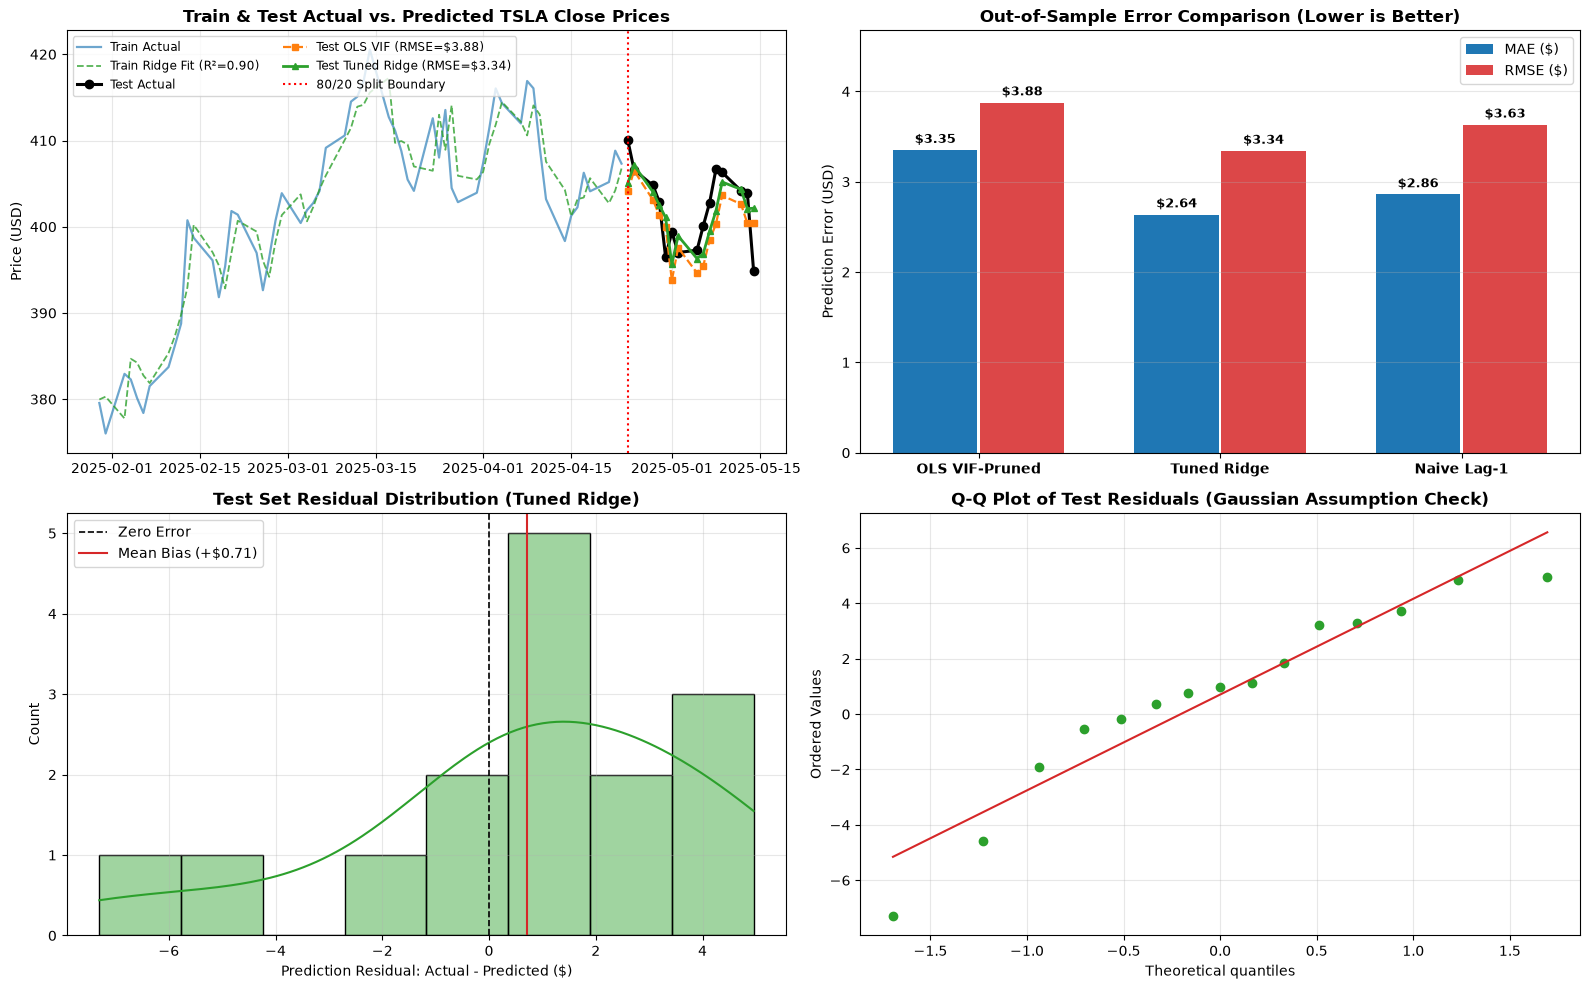

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
test_dates = test_df['Date']

# 1. Full Timeline (Train + Test) Actual vs. Predicted Fit
axes[0, 0].plot(train_df['Date'], y_train, color='#1f77b4', alpha=0.65, linewidth=1.6, label='Train Actual')
axes[0, 0].plot(train_df['Date'], ridge_model.predict(X_tr_all), color='#2ca02c', linestyle='--', alpha=0.8, linewidth=1.3, label='Train Ridge Fit (R²=0.90)')
axes[0, 0].plot(test_dates, y_test, color='black', marker='o', linewidth=2.2, label='Test Actual')
axes[0, 0].plot(test_dates, ols_preds, color='#ff7f0e', linestyle='--', marker='s', markersize=4, linewidth=1.6, label='Test OLS VIF (RMSE=$3.88)')
axes[0, 0].plot(test_dates, ridge_preds, color='#2ca02c', marker='^', markersize=5, linewidth=2.0, label='Test Tuned Ridge (RMSE=$3.34)')
axes[0, 0].axvline(test_dates.min(), color='red', linestyle=':', linewidth=1.5, label='80/20 Split Boundary')
axes[0, 0].set_title('Train & Test Actual vs. Predicted TSLA Close Prices', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Price (USD)')
axes[0, 0].legend(loc='upper left', fontsize=8.5, ncol=2)
axes[0, 0].grid(True, alpha=0.3)

# 2. Out-of-Sample Error Metric Bar Comparison (MAE vs. RMSE)
models_plot = ['OLS VIF-Pruned', 'Tuned Ridge', 'Naive Lag-1']
mae_vals = [
    mean_absolute_error(y_test, ols_preds),
    mean_absolute_error(y_test, ridge_preds),
    mean_absolute_error(y_test, test_df['Close_Lag_1'])
]
rmse_vals = [
    np.sqrt(mean_squared_error(y_test, ols_preds)),
    np.sqrt(mean_squared_error(y_test, ridge_preds)),
    np.sqrt(mean_squared_error(y_test, test_df['Close_Lag_1']))
]
x = np.arange(len(models_plot))
b1 = axes[0, 1].bar(x - 0.18, mae_vals, width=0.35, color='#1f77b4', label='MAE ($)')
b2 = axes[0, 1].bar(x + 0.18, rmse_vals, width=0.35, color='#d62728', alpha=0.85, label='RMSE ($)')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(models_plot, fontweight='bold')
axes[0, 1].set_ylabel('Prediction Error (USD)')
axes[0, 1].set_ylim(0, max(rmse_vals) + 0.8)
axes[0, 1].set_title('Out-of-Sample Error Comparison (Lower is Better)', fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(axis='y', alpha=0.3)
for bar in list(b1) + list(b2):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.08, f"${bar.get_height():.2f}", ha='center', fontsize=9, fontweight='bold')

# 3. Residual Distribution & Mean Bias Check (Tuned Ridge)
ridge_resid = audit_df['Ridge_Error ($)']
sns.histplot(ridge_resid, bins=8, kde=True, color='#2ca02c', alpha=0.45, ax=axes[1, 0])
axes[1, 0].axvline(0, color='black', linestyle='--', linewidth=1.2, label='Zero Error')
axes[1, 0].axvline(ridge_resid.mean(), color='#d62728', linestyle='-', linewidth=1.5, label=f"Mean Bias (+${ridge_resid.mean():.2f})")
axes[1, 0].set_title('Test Set Residual Distribution (Tuned Ridge)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Prediction Residual: Actual - Predicted ($)')
axes[1, 0].legend(loc='upper left')
axes[1, 0].grid(True, alpha=0.3)

# 4. Normal Q-Q Plot of Test Residuals
stats.probplot(ridge_resid, dist='norm', plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_color('#2ca02c')
axes[1, 1].get_lines()[1].set_color('#d62728')
axes[1, 1].set_title('Q-Q Plot of Test Residuals (Gaussian Assumption Check)', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()